# Assignment 1 — Data Exploration and Cleaning: Media

Each row represents a post–media association. We examine structure, missing values, duplicates, consistency, outliers, and opportunities for integration and derived information.

Requirements: Python 3.10+, pandas 2.0+, NumPy, and Matplotlib. Adjust the paths below and run cells in order. Original files remain unchanged. `EXPORT = True` writes compressed CSVs; it is off by default to avoid creating large data copies.


In [1]:
from pathlib import Path
from urllib.parse import urlsplit
import xml.etree.ElementTree as ET
import json
import re
import html
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

PROJECT_DIR = Path(r"C:\Users\bucco\Desktop\Laboratory of Data Science\project")
DATA_DIR = PROJECT_DIR / "Truth-Social-Analysis-and-Data-Warehousing---Decision-Support-Systems-" / "Project_Data"
ARFF_PATH = PROJECT_DIR / "code_project" / "data" / "Additional_Data" / "additional_truths.arff"
EXPORT = False


In [2]:
with (DATA_DIR / "media.json").open(encoding="utf-8") as file:
    data = json.load(file, parse_int=str, parse_float=str)
df_raw = pd.DataFrame(data, dtype="string")
del data
original_columns = df_raw.columns.tolist()
print("Rows and columns:", df_raw.shape)
display(df_raw.head())
display(pd.DataFrame({"Missing": df_raw.isna().sum(), "Blank": [df_raw[c].str.strip().eq("").sum() for c in df_raw], "Distinct": df_raw.nunique()}))


Rows and columns: (257500, 4)


,id_media,media_url,truth_id,media_id
0,2,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/969/670/360/941/179/original/bbbc0aeebd6aa817.jpg,37,2
1,2,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/969/670/360/941/179/original/bbbc0aeebd6aa817.jpg,384189,2
2,2,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/969/670/360/941/179/original/bbbc0aeebd6aa817.jpg,508873,2
3,5,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/937/123/757/612/919/original/c4ad7ceeec32b2cd.jpg,40,5
4,5,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/937/123/757/612/919/original/c4ad7ceeec32b2cd.jpg,386893,5


,Missing,Blank,Distinct
id_media,0,0,184876
media_url,0,0,184876
truth_id,0,0,236490
media_id,0,0,184876


In [3]:
removed_duplicates = int(df_raw.duplicated().sum())
df_clean = df_raw.drop_duplicates().reset_index(drop=True).copy()
for col in df_clean:
    df_clean[col] = df_clean[col].str.strip().replace("", pd.NA)
id_columns = ['id_media', 'media_id', 'truth_id']
for col in id_columns:
    values = df_clean[col].str.replace(r"\.0+$", "", regex=True)
    assert values.str.fullmatch(r"\d+", na=False).all(), f"Inspect invalid {col} values."
    df_clean[col] = pd.to_numeric(values, errors="raise").astype("Int64")
    assert df_clean[col].gt(0).all()
print("Exact duplicate rows removed:", removed_duplicates)
features = pd.DataFrame({"row_id": np.arange(len(df_clean))})


Exact duplicate rows removed: 4


## Media URL quality and identifier mappings

URLs are inspected syntactically without downloading media or assuming that a file is accessible. Query strings are retained. Extensions provide a tentative media type, not a MIME-type or content verification.


In [4]:
def inspect_url(value):
    if pd.isna(value):
        return False, None, None, None
    try:
        parsed = urlsplit(value)
        port = parsed.port
        valid = bool(parsed.scheme.lower() in ["http", "https"] and parsed.hostname
                     and not any(c.isspace() for c in value)
                     and parsed.username is None and parsed.password is None)
        return valid, (parsed.hostname or "").lower().removeprefix("www.") or None, parsed.path, parsed.scheme.lower()
    except ValueError:
        return False, None, None, None


In [5]:
features["media_url_original"] = df_clean["media_url"]
parsed = pd.DataFrame(df_clean["media_url"].map(inspect_url).tolist(), columns=["valid_url", "hostname", "path", "scheme"])
features = pd.concat([features, parsed], axis=1)
features["identifier_mismatch"] = df_clean["id_media"].ne(df_clean["media_id"])
features["url_length"] = df_clean["media_url"].str.len().astype("Int64")
df_clean.loc[~features["valid_url"], "media_url"] = pd.NA
urls_per_id = df_clean.groupby("media_id")["media_url"].nunique()
features["id_has_multiple_urls"] = df_clean["media_id"].map(urls_per_id).gt(1)
print("Invalid URLs retained for review:", (~features["valid_url"]).sum())
print("IDs associated with multiple URLs:", urls_per_id.gt(1).sum())
print("URL values assigned multiple IDs:", df_clean.groupby("media_url")["media_id"].nunique().gt(1).sum())
print("Repeated media–post pairs:", df_clean.duplicated(["truth_id", "media_id"]).sum())


Invalid URLs retained for review: 2
IDs associated with multiple URLs: 0
URL values assigned multiple IDs: 0
Repeated media–post pairs: 0


In [6]:
features["extension"] = features["path"].astype("string").str.extract(r"\.([A-Za-z0-9]+)$", expand=False).str.lower()
features["media_type_hint"] = "unknown"
features.loc[features["extension"].isin(["jpg", "jpeg", "png", "gif", "webp", "avif"]), "media_type_hint"] = "image"
features.loc[features["extension"].isin(["mp4", "webm", "mov", "m4v"]), "media_type_hint"] = "video"
features.loc[features["extension"].isin(["mp3", "m4a", "wav", "ogg"]), "media_type_hint"] = "audio"
display(features["media_type_hint"].value_counts().to_frame("Associations"))
display(features["hostname"].value_counts().head(10).to_frame("Associations"))
display(features["url_length"].describe(percentiles=[.5, .95, .99]).to_frame("URL length"))


,Associations
media_type_hint,
image,257494
unknown,2


,Associations
hostname,
static-assets-1.truthsocial.com,257496


,URL length
count,257496.0
mean,138.523212
std,2.004344
min,138.0
50%,139.0
95%,139.0
99%,139.0
max,835.0


## Post references and recovery assessment

`truth_id` is checked as an internal main-corpus ID first, then against exact ARFF source IDs. A coincidental external-ID match is reported as a candidate, not used to rewrite the foreign key. Missing records in a partial corpus do not establish that the relationship is false.

The ARFF reference reader uses only the leading and trailing metadata fields of the supplied one-record-per-line file. It does not parse post text or claim to be a general ARFF reader.


In [7]:
needed_internal = set(df_clean["truth_id"].astype("string"))
needed_external = needed_internal.copy()


In [8]:
arff_rows = []
in_data = False
with ARFF_PATH.open(encoding="utf-8-sig") as file:
    for line in file:
        line = line.strip()
        if not in_data:
            in_data = line.lower() == "@data"
            continue
        if not line or line.startswith("%"):
            continue
        first = line.split(",", 2)
        tail = line.rsplit(",", 3)
        assert first[0].isdigit() and len(tail) == 4
        arff_rows.append((first[0], tail[1].strip("'\""), tail[2], first[1].strip("'\"")))
arff_ref = pd.DataFrame(arff_rows, columns=["source_id", "external_id", "author", "timestamp"], dtype="string")
del arff_rows
assert arff_ref["source_id"].is_unique
assert arff_ref["source_id"].eq(arff_ref["external_id"]).all()
arff_ref["author"] = pd.to_numeric(arff_ref["author"].str.replace(r"\.0+$", "", regex=True)).astype("Int64")
arff_ref["timestamp"] = pd.to_datetime(arff_ref["timestamp"], format="ISO8601", errors="raise")


In [9]:
main_ids, parts = set(), []
for chunk in pd.read_csv(DATA_DIR / "truths.csv", usecols=["id", "external_id", "url", "author", "timestamp"], dtype="string", keep_default_na=False, chunksize=100000):
    chunk["id"] = chunk["id"].str.replace(r"\.0+$", "", regex=True)
    assert chunk["id"].str.fullmatch(r"\d+", na=False).all()
    main_ids.update(chunk["id"])
    external = chunk["external_id"].where(chunk["external_id"].str.fullmatch(r"\d+", na=False))
    url_id = chunk["url"].str.extract(r"(?i)^https?://(?:www\.)?truthsocial\.com/@[^/?#]+/posts/(\d+)/?$", expand=False)
    url_id = url_id.combine_first(chunk["url"].where(chunk["url"].str.fullmatch(r"\d+", na=False)))
    mismatch = external.notna() & url_id.notna() & external.ne(url_id).fillna(False)
    chunk["external_id"] = external.combine_first(url_id).mask(mismatch)
    keep = chunk["id"].isin(needed_internal) | chunk["external_id"].isin(needed_external)
    parts.append(chunk.loc[keep, ["id", "external_id", "author", "timestamp"]].copy())
main_ref = pd.concat(parts, ignore_index=True).drop_duplicates()
del parts, chunk
main_ref["author"] = pd.to_numeric(main_ref["author"].str.replace(r"\.0+$", "", regex=True).replace("", pd.NA), errors="raise").astype("Int64")
main_ref["timestamp"] = pd.to_datetime(main_ref["timestamp"], format="ISO8601", errors="raise")
print("Distinct main-corpus IDs:", len(main_ids))


Distinct main-corpus IDs: 1038821


In [10]:
truth_keys = df_clean["truth_id"].astype("string")
features["post_reference_status"] = "missing"
features.loc[truth_keys.isin(main_ids), "post_reference_status"] = "main_internal"
arff_match = ~truth_keys.isin(main_ids) & truth_keys.isin(arff_ref["source_id"])
features.loc[arff_match, "post_reference_status"] = "arff_source_id"
external_candidate = ~truth_keys.isin(main_ids) & truth_keys.isin(main_ref["external_id"])
features["external_namespace_candidate"] = external_candidate
unresolved_post = features["post_reference_status"].eq("missing")
display(features["post_reference_status"].value_counts().to_frame("Relationships"))
print("Unresolved rows with an external-ID candidate:", (unresolved_post & external_candidate).sum())
display(df_clean.loc[unresolved_post].head(5))


Unresolved rows with an external-ID candidate: 0


,Relationships
post_reference_status,
main_internal,155188
missing,102308


,id_media,media_url,truth_id,media_id
455,67,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/097/748/144/321/366/original/c72b9d71501fa87c.jpeg,112,67
456,67,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/097/748/144/321/366/original/c72b9d71501fa87c.jpeg,114431,67
457,67,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/097/748/144/321/366/original/c72b9d71501fa87c.jpeg,120836,67
458,67,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/097/748/144/321/366/original/c72b9d71501fa87c.jpeg,158929,67
459,67,https://static-assets-1.truthsocial.com/tmtg:prime-ts-assets/media_attachments/files/108/097/748/144/321/366/original/c72b9d71501fa87c.jpeg,162173,67


,Distinct media per linked post
count,236490.000000
mean,1.088824
std,0.425777
min,1.000000
50%,1.000000
90%,1.000000
95%,2.000000
99%,4.000000
max,8.000000


,Media items
truth_id,
537257,8
538696,6
106097,5
180151,5
530231,5
530238,5
531300,5
533700,5
533894,5


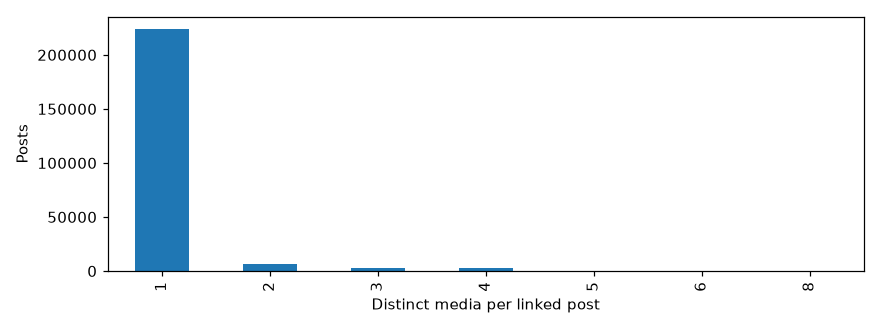

In [11]:
media_per_post = df_clean.groupby("truth_id")["media_id"].nunique()
display(media_per_post.describe(percentiles=[.5, .9, .95, .99]).to_frame("Distinct media per linked post"))
display(media_per_post.nlargest(10).to_frame("Media items"))
q1, q3 = media_per_post.quantile([.25, .75])
features["many_media_on_post"] = df_clean["truth_id"].isin(media_per_post[media_per_post > q3 + 1.5 * (q3 - q1)].index)
media_per_post.value_counts().sort_index().plot.bar(figsize=(8, 3))
plt.xlabel("Distinct media per linked post")
plt.ylabel("Posts")
plt.tight_layout()
plt.show()


## Final validation and exports

We preserve the original column structure. Features retain `row_id`, the zero-based row position in the cleaned export. Unresolved links remain in the cleaned data and are also listed for review.


In [12]:
df_final = df_clean[original_columns].copy()
assert len(df_final) == len(df_raw) - removed_duplicates
assert df_final[id_columns].notna().all().all()
assert df_final[id_columns].gt(0).all().all()
assert len(features) == len(df_final)
assert features["row_id"].tolist() == list(range(len(df_final)))
review_mask = (
    unresolved_post
    | ~features["valid_url"]
    | features["identifier_mismatch"]
    | features["id_has_multiple_urls"]
)
issues = pd.concat([features.loc[review_mask], df_final.loc[review_mask]], axis=1)
quality_summary = pd.Series({
    "Original rows": len(df_raw), "Exact duplicates removed": removed_duplicates,
    "Cleaned rows": len(df_final), "Rows for review": int(review_mask.sum()),
    "Missing cells after cleaning": int(df_final.isna().sum().sum())
}, name="Count")
display(quality_summary.to_frame())


,Count
Original rows,257500
Exact duplicates removed,4
Cleaned rows,257496
Rows for review,102310
Missing cells after cleaning,2


In [13]:
OUTPUT_DIR = Path.cwd() / "output_media"
if EXPORT:
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    df_final.to_csv(OUTPUT_DIR / "media_clean.csv.gz", index=False, chunksize=50000)
    features.to_csv(OUTPUT_DIR / "media_features.csv.gz", index=False, chunksize=50000)
    issues.to_csv(OUTPUT_DIR / "media_issues.csv.gz", index=False)
    quality_summary.to_csv(OUTPUT_DIR / "media_quality_summary.csv", index_label="Check")
    print("Exported to:", OUTPUT_DIR.resolve())
else:
    print("Analysis and cleaning complete. Set EXPORT = True to save datasets.")


Analysis and cleaning complete. Set EXPORT = True to save datasets.


## Conclusions and Assignment 1 coverage

**Observed results:** Original rows: 257,500; Exact duplicates removed: 4; Cleaned rows: 257,496; Rows for review: 102,310; Missing cells after cleaning: 2.

The cleaned association table preserves media and post IDs. URL validity, hostname, length, extension, and tentative media type are separate features. Unmatched post references remain available for later integration. No image content, copyright, location, or creation date is inferred from a URL; this source has no event timestamp. Extreme media counts are retained, and media presence does not recover missing post text.

This notebook covers structure and types, missing values, duplicates and mappings, data-specific anomalies, outliers, post/user integrity where applicable, recovery assessments, derived features, and validated cleaning. Only supplied files are used. The full ARFF-to-Truths integration is implemented in `04_additional_truths_complete.ipynb`; this notebook's reference checks do not replace it.

Compressed CSVs are readable directly with `pd.read_csv(path)`. Original invalid values and unresolved cases remain traceable in features or issue tables. The sources are the supplied dataset, related original datasets, the Assignment 1 instructions, and its original exploration/cleaning notebooks.
